# Moderator scan — exploratory appendix

**Status: exploratory.** This notebook is a completeness check for the SDL 2026 paper, *not* new headline analysis. It maps which demographic/political moderators show confidence-transition patterns across WVS Turkey waves, beyond the religiosity result documented in `results/partner_handoff.md` (army/police/courts trust split by religiosity, dated to 2001).

Design mirrors the Step 6 long-window ordinal logit (`layer4b_longwindow.py`): WV2 baseline, same analysis sample (cluster non-missing), same controls minus the moderator itself, moderator × wave interactions, Benjamini–Hochberg correction applied across the **entire** scan grid.

Rules honoured: no existing output files are modified; main models are not re-run or altered. New outputs only: `results/figs_scan/` and `results/moderator_scan_grid.csv`.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.multitest import multipletests

warnings.filterwarnings("ignore")

ROOT, RESULTS = ".", "results"
FIGS = os.path.join(RESULTS, "figs_scan")
os.makedirs(FIGS, exist_ok=True)

WAVES = ["WV2", "WV3", "WV4", "WV5", "WV6", "WV7"]
YEARS = {"WV2": 1990, "WV3": 1996, "WV4": 2001, "WV5": 2007, "WV6": 2011, "WV7": 2018}
INST = ["conf_military", "conf_police", "conf_courts"]  # reverse-coded: higher = more confidence
INST_LABEL = {"conf_military": "Army", "conf_police": "Police", "conf_courts": "Courts"}

df = pd.read_csv(os.path.join(RESULTS, "pooled_extended_v2.csv"))
df = df.dropna(subset=["cluster"]).copy()          # same analysis sample as layer4b
df["not_religious_dummy"] = df["rel_person"].map(
    lambda v: 1 if v in (2, 3) else (0 if v == 1 else np.nan))
df["birth_year"] = df["year"] - df["age"]
print(f"Analysis sample: n = {len(df)} (pooled file 11,704 minus cluster-missing)")

Analysis sample: n = 11311 (pooled file 11,704 minus cluster-missing)


## 1. Moderator inventory

Candidates checked against per-wave coverage; rule: drop any moderator missing (or uninformative) in 3+ waves.

- **Kept (5):** gender, birth cohort (bands, not age), education, income, left–right placement.
- **Dropped — party preference:** `party_recode` is `pre_AKP_era` for all of WV2–WV4, so it is uninformative in 3 of 6 waves and cannot enter a WV2-baseline interaction design.
- **Unavailable — town size:** no settlement-size column exists in `pooled_extended_v2.csv` (confirmed against `column_manifest_v2.csv`).
- Note: `conf_courts` was not asked in WV4, so courts models lose the WV4 interaction cell throughout.

In [2]:
cands = ["female", "age", "education_recode", "income_raw", "left_right", "party_recode"]
cov = (df.groupby("wave")[cands].apply(lambda g: g.notna().mean().round(3))).loc[WAVES]
# party_recode: non-missing but uninformative WV2-WV4 -> report informative share instead
cov["party_recode"] = df.groupby("wave")["party_recode"].apply(
    lambda s: round((~s.isna() & (s != "pre_AKP_era")).mean(), 3)).loc[WAVES]
cov.columns = ["gender", "age (→cohort)", "education", "income", "left_right",
               "party (informative share)"]
cov

,gender,age (→cohort),education,income,left_right,party (informative share)
wave,,,,,,
WV2,1.0,0.996,0.934,0.984,0.894,0.000
WV3,1.0,0.999,0.857,0.988,0.937,0.000
WV4,1.0,0.999,0.835,0.941,0.960,0.000
WV5,1.0,1.000,0.886,0.984,0.861,0.642
WV6,1.0,1.000,0.851,0.980,0.915,0.770
WV7,1.0,1.000,0.997,0.970,0.893,0.921


### Moderator coding

Descriptive bands and, for the formal layer, one binary contrast per moderator (mirrors the `not_religious_dummy` design → one interaction coefficient per wave):

| Moderator | Descriptive bands | Formal contrast | Caveat |
|---|---|---|---|
| Gender | male / female | female = 1 | — |
| Birth cohort | pre-1950 / 1950–64 / 1965–79 / 1980+ | born ≥ 1965 = 1 | **APC confound**: cohort = year − age, so cohort × wave is not separable from aging in a repeated cross-section; read as descriptive, not causal. 1980+ band structurally absent in WV2–WV3. |
| Education | low / med / high (`education_recode`) | high (= 3) = 1 | **WV7 ISCED break** (manifest): WV7 uses a different scale mapped through the same cutoffs, so education × WV7 cells are confounded with the recode change. |
| Income | 1–3 / 4–6 / 7–10 (subjective decile) | ≥ 5 = 1 | subjective scale; wave medians drift 3–6 |
| Left–right | left 1–4 / center 5–6 / right 7–10 | right (≥ 7) = 1 | — |

The WV7 measurement caveat (`wv7_flag`) applies to every WV7 cell; as in `layer4b_longwindow.py`, the `wave_WV7` dummy absorbs the flag (they are perfectly collinear), so WV7 interactions are reported with the caveat rather than a separate covariate.

In [3]:
df["mod_gender"]    = df["female"]
df["mod_cohort"]    = np.where(df["birth_year"].isna(), np.nan, (df["birth_year"] >= 1965).astype(float))
df["mod_education"] = np.where(df["education_recode"].isna(), np.nan, (df["education_recode"] == 3).astype(float))
df["mod_income"]    = np.where(df["income_raw"].isna(), np.nan, (df["income_raw"] >= 5).astype(float))
df["mod_leftright"] = np.where(df["left_right"].isna(), np.nan, (df["left_right"] >= 7).astype(float))

BANDS = {
    "mod_gender":    ("Gender", df["female"].map({0: "Male", 1: "Female"})),
    "mod_cohort":    ("Birth cohort", pd.cut(df["birth_year"], [1890, 1949, 1964, 1979, 2005],
                                             labels=["pre-1950", "1950-64", "1965-79", "1980+"])),
    "mod_education": ("Education", df["education_recode"].map({1: "Low", 2: "Medium", 3: "High"})),
    "mod_income":    ("Income (subjective)", pd.cut(df["income_raw"], [0, 3, 6, 10],
                                                    labels=["Low (1-3)", "Mid (4-6)", "High (7-10)"])),
    "mod_leftright": ("Left-right", pd.cut(df["left_right"], [0, 4, 6, 10],
                                           labels=["Left (1-4)", "Center (5-6)", "Right (7-10)"])),
}
for m, (_, s) in BANDS.items():
    df[f"band_{m}"] = s
print({m: int(df[m].sum()) for m in ["mod_gender", "mod_cohort", "mod_education",
                                     "mod_income", "mod_leftright"]})

{'mod_gender': 5578, 'mod_cohort': 6782, 'mod_education': 2780, 'mod_income': 4507, 'mod_leftright': 4056}


## 2. Descriptive layer

Mean confidence per institution × wave × moderator group (cells with n < 30 masked). One small-multiples figure per moderator, saved to `results/figs_scan/`. Reminder when reading education: the WV7 dip/jump in group composition is the ISCED recode, not a real shift.

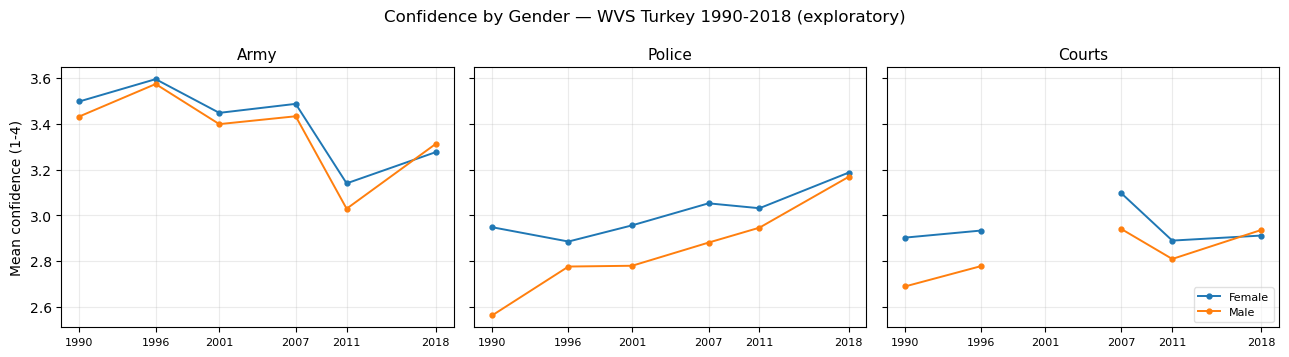

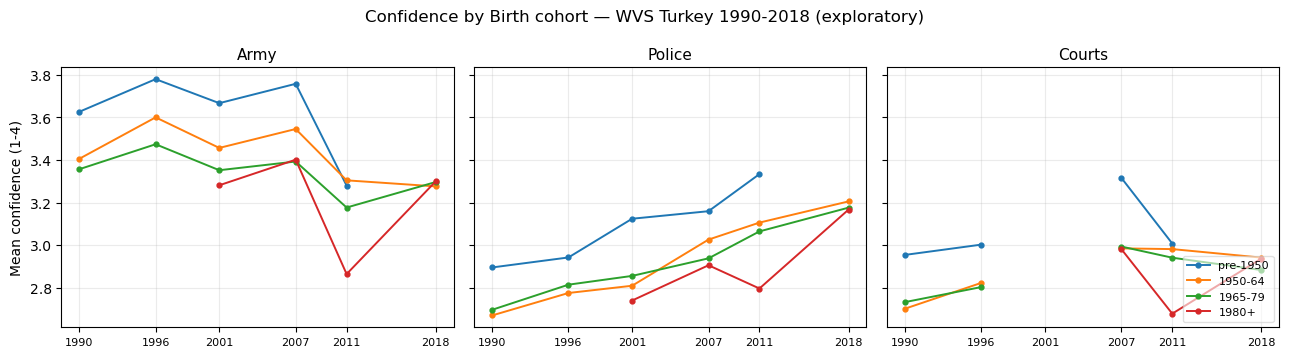

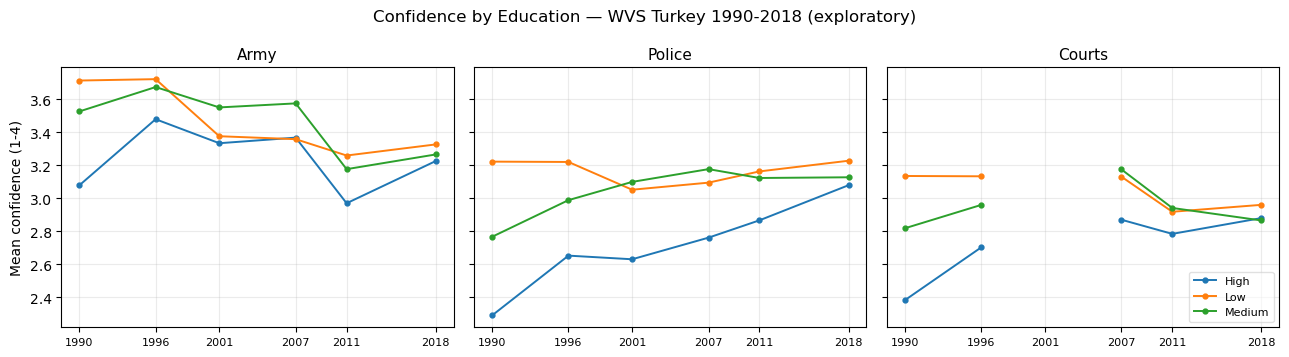

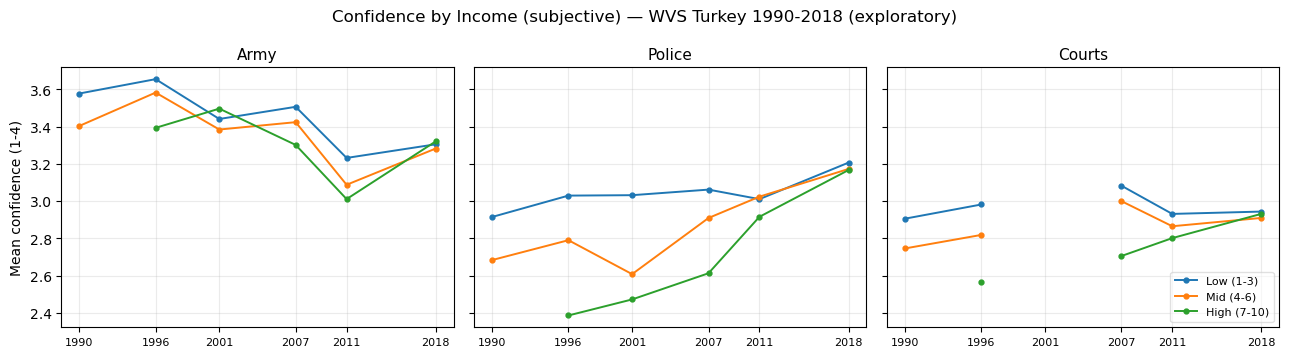

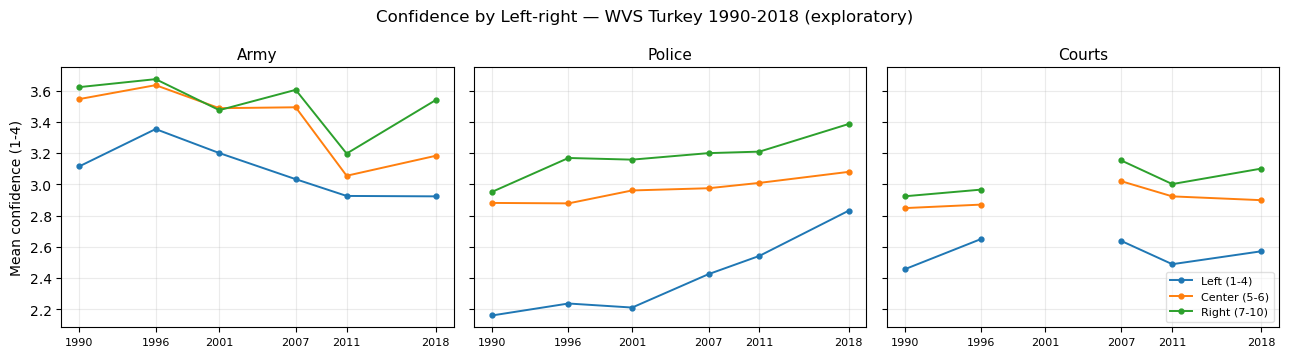

Figures saved to results/figs_scan/


In [4]:
xs = [YEARS[w] for w in WAVES]
for m, (label, _) in BANDS.items():
    bcol = f"band_{m}"
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for ax, inst in zip(axes, INST):
        g = (df.groupby(["wave", bcol], observed=True)[inst]
               .agg(["mean", "count"]).reset_index())
        g.loc[g["count"] < 30, "mean"] = np.nan
        if isinstance(df[bcol].dtype, pd.CategoricalDtype):
            groups = list(df[bcol].cat.categories)
        else:
            groups = sorted(df[bcol].dropna().unique())
        for grp in groups:
            sub = g[g[bcol] == grp].set_index("wave").reindex(WAVES)
            ax.plot(xs, sub["mean"], marker="o", ms=3.5, lw=1.4, label=str(grp))
        ax.set_title(INST_LABEL[inst], fontsize=11)
        ax.set_xticks(xs); ax.tick_params(axis="x", labelsize=8)
        ax.grid(alpha=0.25)
    axes[0].set_ylabel("Mean confidence (1-4)")
    axes[-1].legend(fontsize=8, loc="lower right", framealpha=0.6)
    fig.suptitle(f"Confidence by {label} — WVS Turkey 1990-2018 (exploratory)", fontsize=12)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGS, f"scan_{m.replace('mod_', '')}.png"), dpi=150,
                bbox_inches="tight")
    plt.show()
print("Figures saved to results/figs_scan/")

## 3. Formal layer

Per moderator × institution: the Step 6 long-window ordinal logit (WV2 baseline), with the religiosity interaction block replaced by moderator × wave interactions. Controls are identical to `layer4b_longwindow.py` (`not_religious_dummy`, `rel_attendance`, `rel_importance_god`, `left_right`, `age`, `female`, `education_raw`, `income_raw`, `married_dummy`, wave dummies) **minus the moderator itself**. Religiosity stays in as main-effect controls only — so a moderator correlated with religiosity (education especially) can partially proxy the headline religiosity × wave dynamic; interactions here are net of religiosity *levels*, not of its *trend*.

15 models (5 moderators × 3 institutions), 70 interaction tests (courts has no WV4 cell), BH applied across all 70. Output: `results/moderator_scan_grid.csv`.

In [5]:
LATER = ["WV3", "WV4", "WV5", "WV6", "WV7"]
for w in LATER:
    df[f"wave_{w}"] = (df["wave"] == w).astype(int)

CONTROLS = ["not_religious_dummy", "rel_attendance", "rel_importance_god", "left_right",
            "age", "female", "education_raw", "income_raw", "married_dummy"]
DROP_CONTROL = {"mod_gender": ["female"], "mod_cohort": ["age"],
                "mod_education": ["education_raw"], "mod_income": ["income_raw"],
                "mod_leftright": ["left_right"]}

rows = []
for mod, dropped in DROP_CONTROL.items():
    ctrl = [c for c in CONTROLS if c not in dropped]
    for w in LATER:
        df[f"mx_{w}"] = df[mod] * df[f"wave_{w}"]
    preds = [mod] + ctrl + [f"wave_{w}" for w in LATER] + [f"mx_{w}" for w in LATER]
    for inst in INST:
        sub = df[[inst] + preds].dropna().copy()
        sub[inst] = sub[inst].astype(int)
        keep = [p for p in preds if sub[p].nunique() > 1]
        res = OrderedModel(sub[inst], sub[keep], distr="logit").fit(
            method="bfgs", maxiter=400, disp=False)
        assert res.mle_retvals.get("converged", False), f"non-convergence: {mod}/{inst}"
        for w in LATER:
            key = f"mx_{w}"
            if key not in res.params.index:
                continue  # courts x WV4: outcome not asked
            rows.append({"moderator": mod.replace("mod_", ""), "institution": inst,
                         "wave": w, "coef": float(res.params[key]),
                         "se": float(res.bse[key]), "p_raw": float(res.pvalues[key]),
                         "n_obs": len(sub)})
        print(f"  fitted {mod.replace('mod_', ''):10s} × {INST_LABEL[inst]:7s}  n={len(sub)}")

grid = pd.DataFrame(rows)
rej, p_adj, _, _ = multipletests(grid["p_raw"], alpha=0.05, method="fdr_bh")
grid["p_bh"], grid["bh_sig"] = p_adj, rej
grid = grid[["moderator", "institution", "wave", "coef", "se", "p_raw", "p_bh",
             "bh_sig", "n_obs"]]
grid.to_csv(os.path.join(RESULTS, "moderator_scan_grid.csv"), index=False)
print(f"\n{len(grid)} tests, {int(grid['bh_sig'].sum())} BH-significant (q < .05) "
      f"-> results/moderator_scan_grid.csv")

  fitted gender     × Army     n=8915


  fitted gender     × Police   n=8911


  fitted gender     × Courts   n=6231


  fitted cohort     × Army     n=8915


  fitted cohort     × Police   n=8911


...

  fitted income     × Police   n=8911


  fitted income     × Courts   n=6231


  fitted leftright  × Army     n=8915


  fitted leftright  × Police   n=8911


  fitted leftright  × Courts   n=6231

70 tests, 25 BH-significant (q < .05) -> results/moderator_scan_grid.csv


In [6]:
sig = grid[grid["bh_sig"]].sort_values("p_bh")
display(sig.round(4).reset_index(drop=True))
print("Min BH-adjusted p per moderator × institution (flat cells stand out):")
grid.pivot_table(index="moderator", columns="institution", values="p_bh",
                 aggfunc="min").round(3)

,moderator,institution,wave,coef,se,p_raw,p_bh,bh_sig,n_obs
0,gender,conf_police,WV6,-0.8836,0.1698,0.0000,0.0000,True,8911
1,gender,conf_police,WV7,-0.7989,0.1600,0.0000,0.0000,True,8911
2,education,conf_military,WV6,1.0245,0.2180,0.0000,0.0001,True,8160
3,education,conf_military,WV7,0.8946,0.2164,0.0000,0.0006,True,8160
4,gender,conf_police,WV4,-0.5737,0.1531,0.0002,0.0025,True,8911
5,gender,conf_police,WV3,-0.6144,0.1696,0.0003,0.0026,True,8911
6,education,conf_courts,WV6,0.7881,0.2168,0.0003,0.0026,True,5743
7,education,conf_military,WV4,0.7642,0.2073,0.0002,0.0026,True,8160
8,education,conf_military,WV5,0.8303,0.2327,0.0004,0.0028,True,8160
9,gender,conf_courts,WV7,-0.5619,0.1609,0.0005,0.0033,True,6231


Min BH-adjusted p per moderator × institution (flat cells stand out):


institution,conf_courts,conf_military,conf_police
moderator,,,
cohort,0.192,0.027,0.143
education,0.003,0.000,0.009
gender,0.003,0.141,0.000
income,0.188,0.049,0.120
leftright,0.031,0.007,0.017


## 4. Summary

BH-significant (q < .05) moderator × institution wave shifts, WV2 baseline:

| Moderator × institution | Sig. waves | Sign | One-line reading |
|---|---|---|---|
| Gender × police | WV3–WV7 (all) | − | Women's police confidence declined relative to men from 1996 on (largest 2011–2018, β ≈ −0.88/−0.80); the police-trust convergence in the handoff is concentrated among men. |
| Gender × courts | WV6, WV7 | − | Same direction, later and weaker; gender × **army is flat** — the army's gender gap is stable across all waves. |
| Education × army | WV3–WV7 (all) | + | High-education respondents' relative army confidence rose from 1996 onward (β +0.65 to +1.02) — parallels the religiosity realignment and, since the scan controls religiosity levels but not its trend, partially proxies it. Does not hinge on the WV7 ISCED cell (WV3–WV6 all significant). |
| Education × police / courts | WV6–WV7 only | + | Late, weaker echoes; WV7 cells carry the ISCED caveat. |
| Left–right × army / police / courts | WV7 (police also WV3) | + | Right self-placement is associated with relative confidence gains in **all three** institutions by 2018 — consistent with AKP-era alignment; every one of these cells carries the WV7 measurement caveat. |
| Cohort × army | WV3–WV6 | − | Post-1965 cohorts relatively less army-confident mid-period (β ≈ −0.50), gone by WV7; APC-confounded, descriptive only. |
| Income × army | WV6 only | + | Single borderline cell (adj. p = .049); treat as noise-adjacent. |

**Flat moderators (a finding in itself):** income is essentially flat everywhere (police and courts entirely; army only the one borderline WV6 cell), cohort is flat for police and courts, and gender is flat for the army. No demographic moderator reproduces the religiosity pattern — a large, multi-wave realignment specific to the army with a simultaneously *stable* courts gradient.

**Consistency with the handoff:** nothing here contradicts the headline. The army-religiosity dissolution (nr × WV4 = +0.72***) remains the distinctive result; the education × army pattern is its socially correlated shadow, and the gender × police decline is secondary structure within the convergence mechanism (handoff finding A) worth one appendix sentence. The scan supports a *qualified* version of the specificity claim: the split is religiosity-specific rather than generically demographic (income, cohort, gender show nothing comparable), while education — religiosity's closest correlate — partially tracks it, as expected.